# 12 Network models

## Random graphs and small worlds

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 12.3-12.4 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Erdős–Rényi and Watts–Strogatz graphs.

**Seminal reading:** Watts & Strogatz (1998),
[*Collective dynamics of ‘small-world’ networks*](https://doi.org/10.1038/30918),
*Nature* **393**, 440–442. 

## 12.3 Erdős–Rényi random graphs

Parameters:

- $n$: number of nodes
- $p$: independent probability for each of the $n(n-1)/2$ possible undirected edges to be included in the graph

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom

from pathlib import Path
import sys
sys.path.insert(0, "../12_modules")

import network_models as nm
import nm_visualize as vis

In [2]:
n = 40
p = 0.10
A = np.zeros((n, n), dtype=int)
for i in range(n):
    for j in range(i + 1, n):
        if np.random.random() < p:
            A[i, j] = 1
            A[j, i] = 1
G_er = nx.from_numpy_array(A)

Let's plot the graph

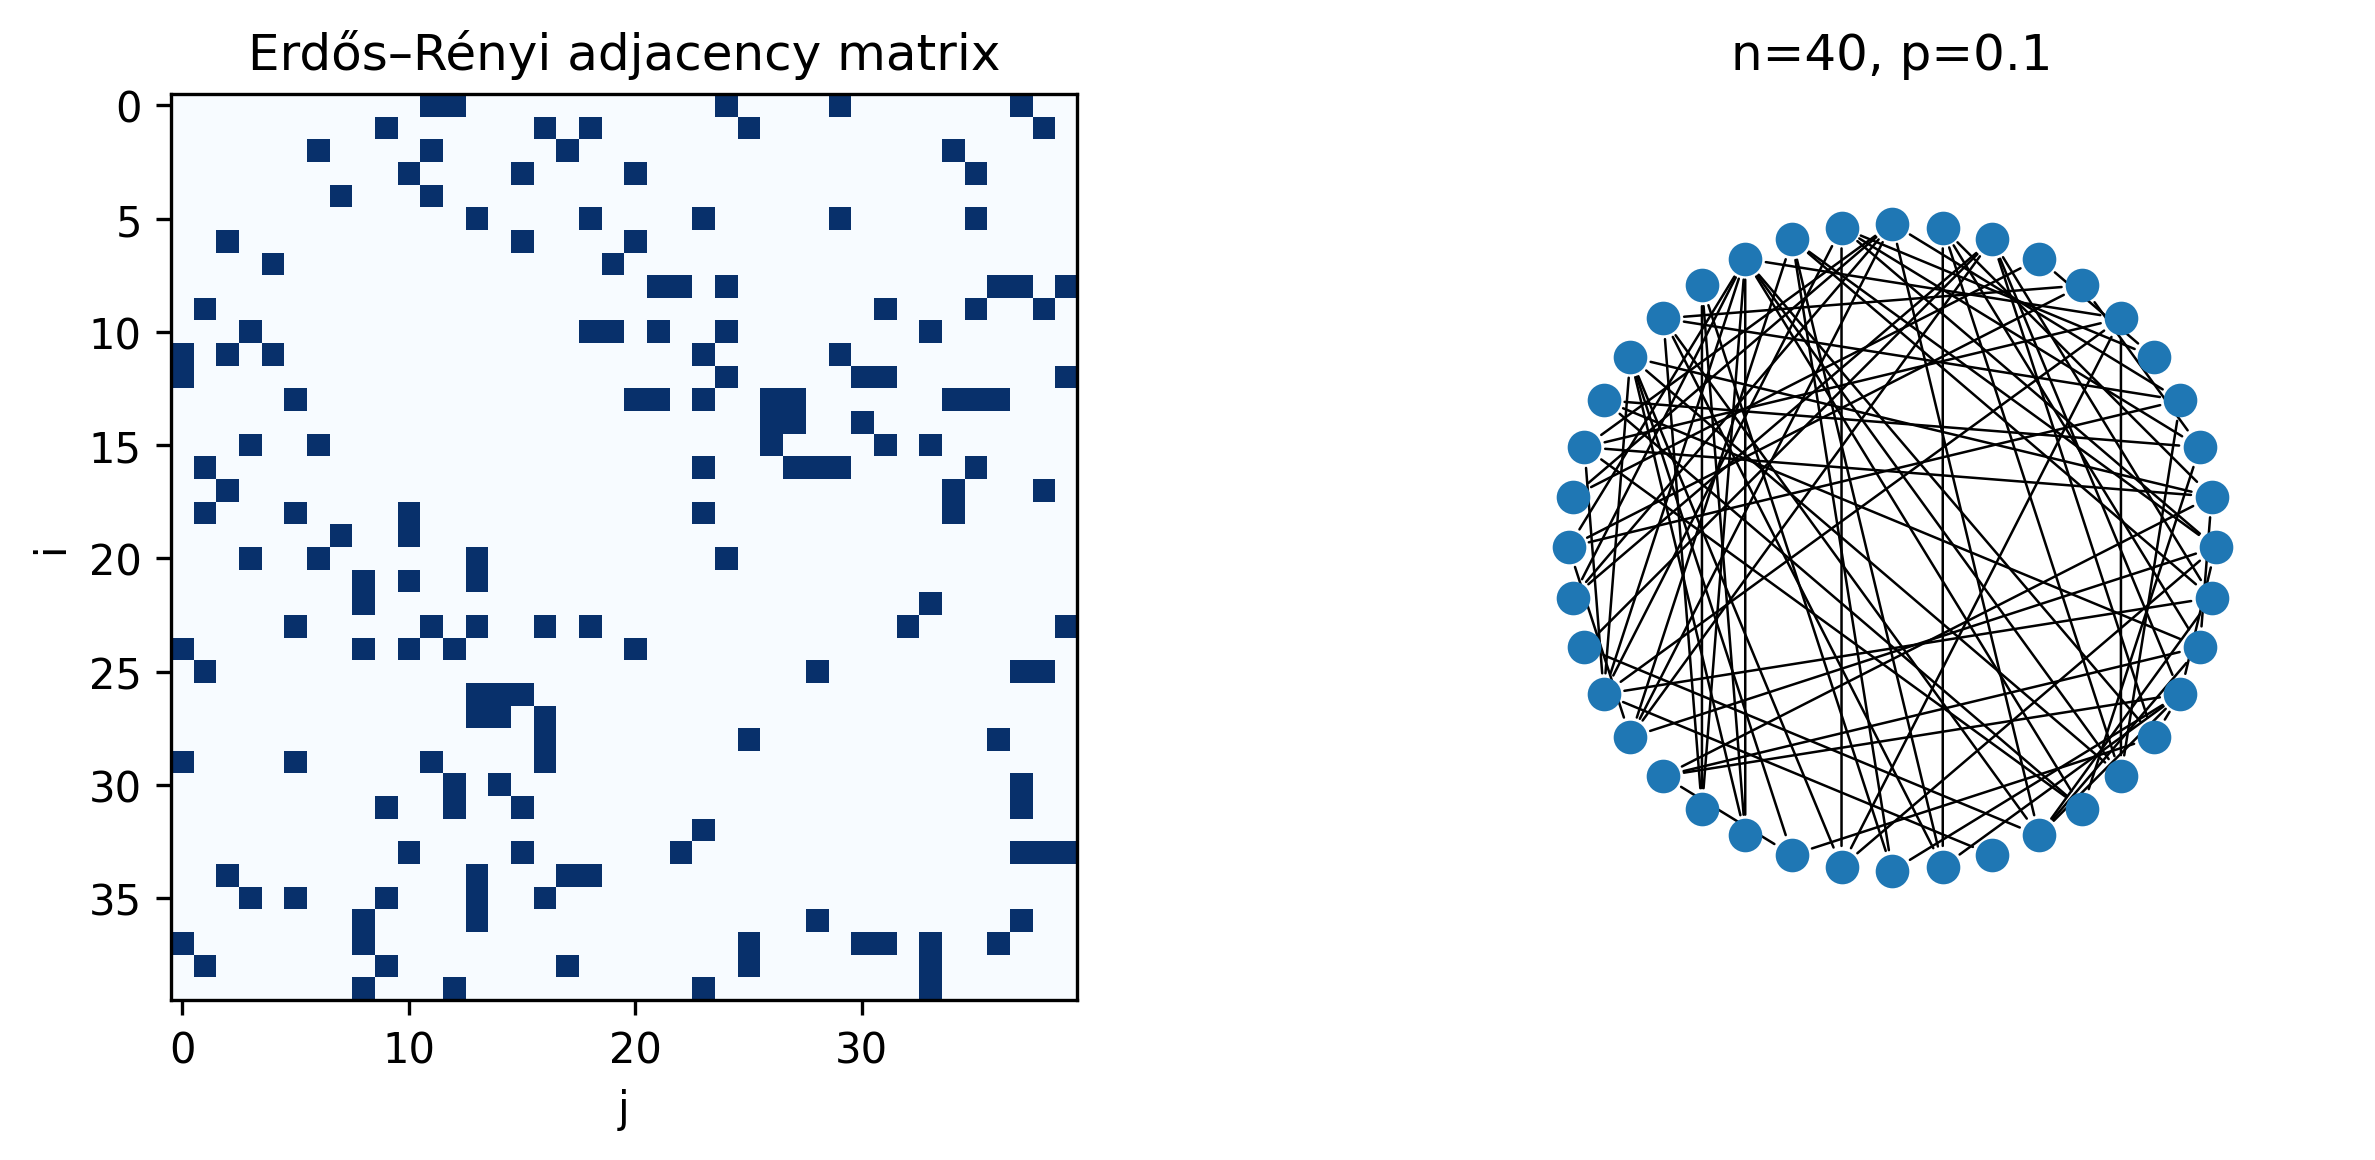

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

axes[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
axes[0].set(
    title="Erdős–Rényi adjacency matrix", 
    xlabel="j", 
    ylabel="i"
)
vis.draw_network_dots(G_er, ax=axes[1])
axes[1].set_title(f"n={n}, p={p}")
plt.show()

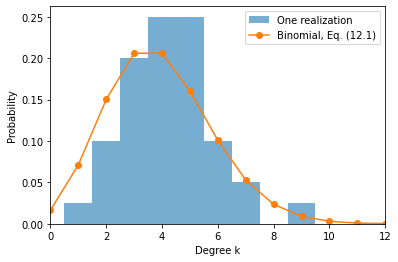

In [4]:
degrees = np.array([degree for _, degree in G_er.degree()])
k_values = np.arange(n)
expected_prob = binom.pmf(k_values, n - 1, p)

plt.hist(degrees, bins=np.arange(n + 1) - 0.5, density=True,
         alpha=0.6, label="One realization")
plt.plot(k_values, expected_prob, "o-", label="Binomial, Eq. (12.1)")

plt.xlim(0, max(12, degrees.max() + 2))
plt.xlabel("Degree k")
plt.ylabel("Probability")
plt.legend()
plt.show()

For $n\to\infty$ with $(n-1)p$ fixed, the binomial tends to a **Poisson** law. 

For $n\to\infty$ with $(n-1)p\to\infty$, the binomial tends to a **Gaussian**. 

Let's use the module 

In [5]:
n = 300
p = 0.015

G_er_large = nm.erdos_renyi(n=n, p=p)

measured = np.array([degree for _, degree in G_er_large.degree()])

expected = (n - 1) * p

print(f"Measured mean degree: {measured.mean():.3f}")
print(f"Expected mean degree: {expected:.3f}")

Measured mean degree: 4.387
Expected mean degree: 4.485


### Exercise 12.4

How the mean path length $l$ and the clustering coefficient $C$ for the Erdős-Rényi random graph depend on the probability $p$

In [6]:
n = 200

p_sparse = np.unique(np.round(np.geomspace(0.01, 0.1, 8), 3))
p_dense = np.unique(np.round(np.geomspace(0.1, 1, 10), 3))

p_values = np.unique(np.hstack((p_sparse, p_dense)))

repetitions = 4

l = []  # mean path length
C = []  # clustering coefficient
for probability in p_values:
    runs = [nm.graph_summary(nm.erdos_renyi(n, probability))
            for _ in range(repetitions)]
    l.append(np.mean([r["mean_path_lcc"] for r in runs]))
    C.append(np.mean([r["C"] for r in runs]))

Theory:

In [7]:
p_ref = np.geomspace(0.01, 1, 100)

# p "sparse"
l_sparse = (np.log(n) - np.euler_gamma) / np.log(p_ref * (n - 1)) +0.5

# p "dense"
l_dense = 2 - p_ref

Let's plot the mean path length $l$ and the clustering coefficient $C$ for the Erdös-Rényi random graph

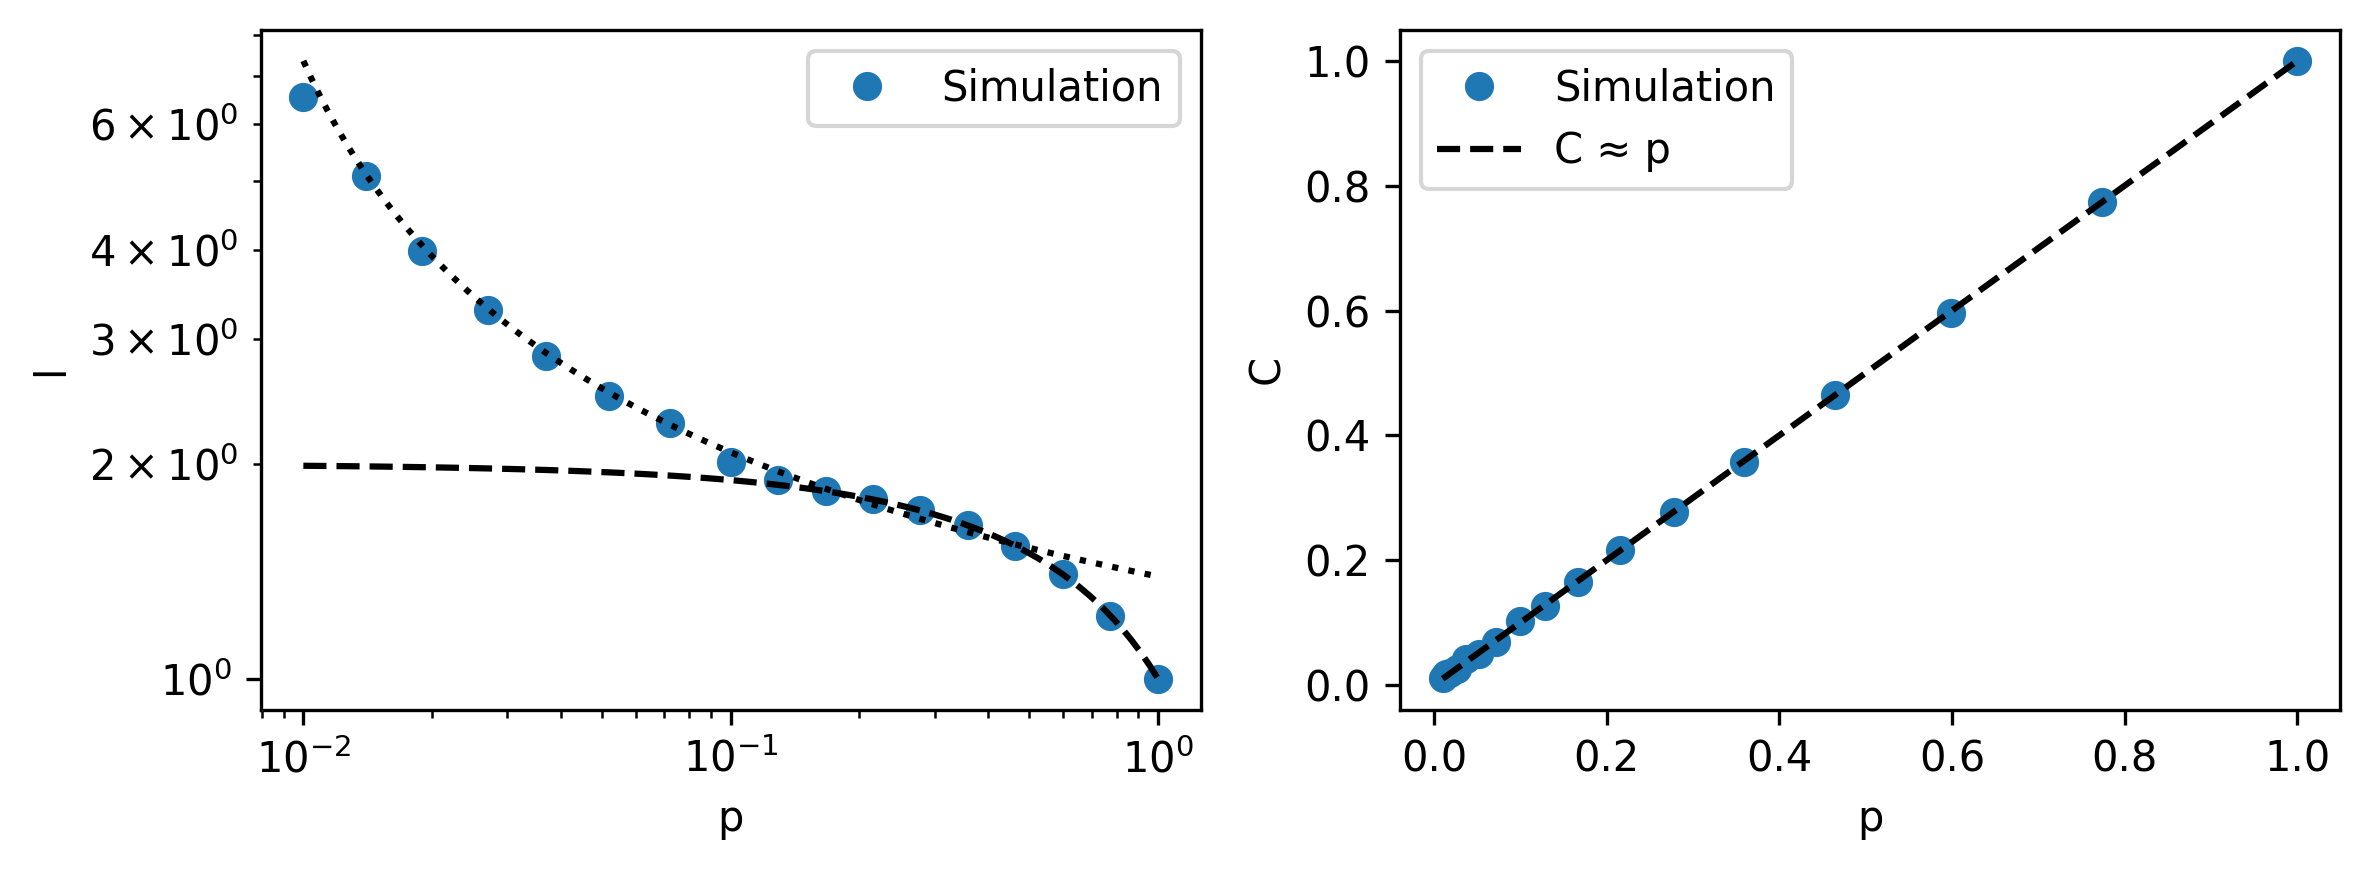

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=300)

axes[0].plot(p_values, l, "o", label="Simulation")
axes[0].plot(p_ref, l_sparse, "k:", "Theory (sparse)")
axes[0].plot(p_ref, l_dense, "k--", "Theory (dense)")
axes[0].set(xlabel="p", ylabel="l")
axes[0].legend()
axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[1].plot(p_values, C, "o", label="Simulation")
axes[1].plot(p_values, p_values, "k--", label="C ≈ p")
axes[1].set(xlabel="p", ylabel="C")
axes[1].legend()

plt.tight_layout()
plt.show()

## 12.4 Watts–Strogatz small-world graphs

Parameters:

- $n$: number of nodes
- $c$: number of initial links ($c$ is even)
- $p$: probability of rewiring each original edge. 


In [9]:
n = 10
c = 4
p = 0.2

A = np.zeros((n, n), dtype=int)
for i in range(n):
    for j in range(i + 1, i + 1 + c//2):
            A[i, j % n] = 1
            A[j % n, i] = 1
            
G_ws_0 = nx.from_numpy_array(A)

A_0 = A.copy()

print(f"Number of edges: {A.sum() / 2}")
print(f"expected: {n * c // 2}")

Number of edges: 20.0
expected: 20


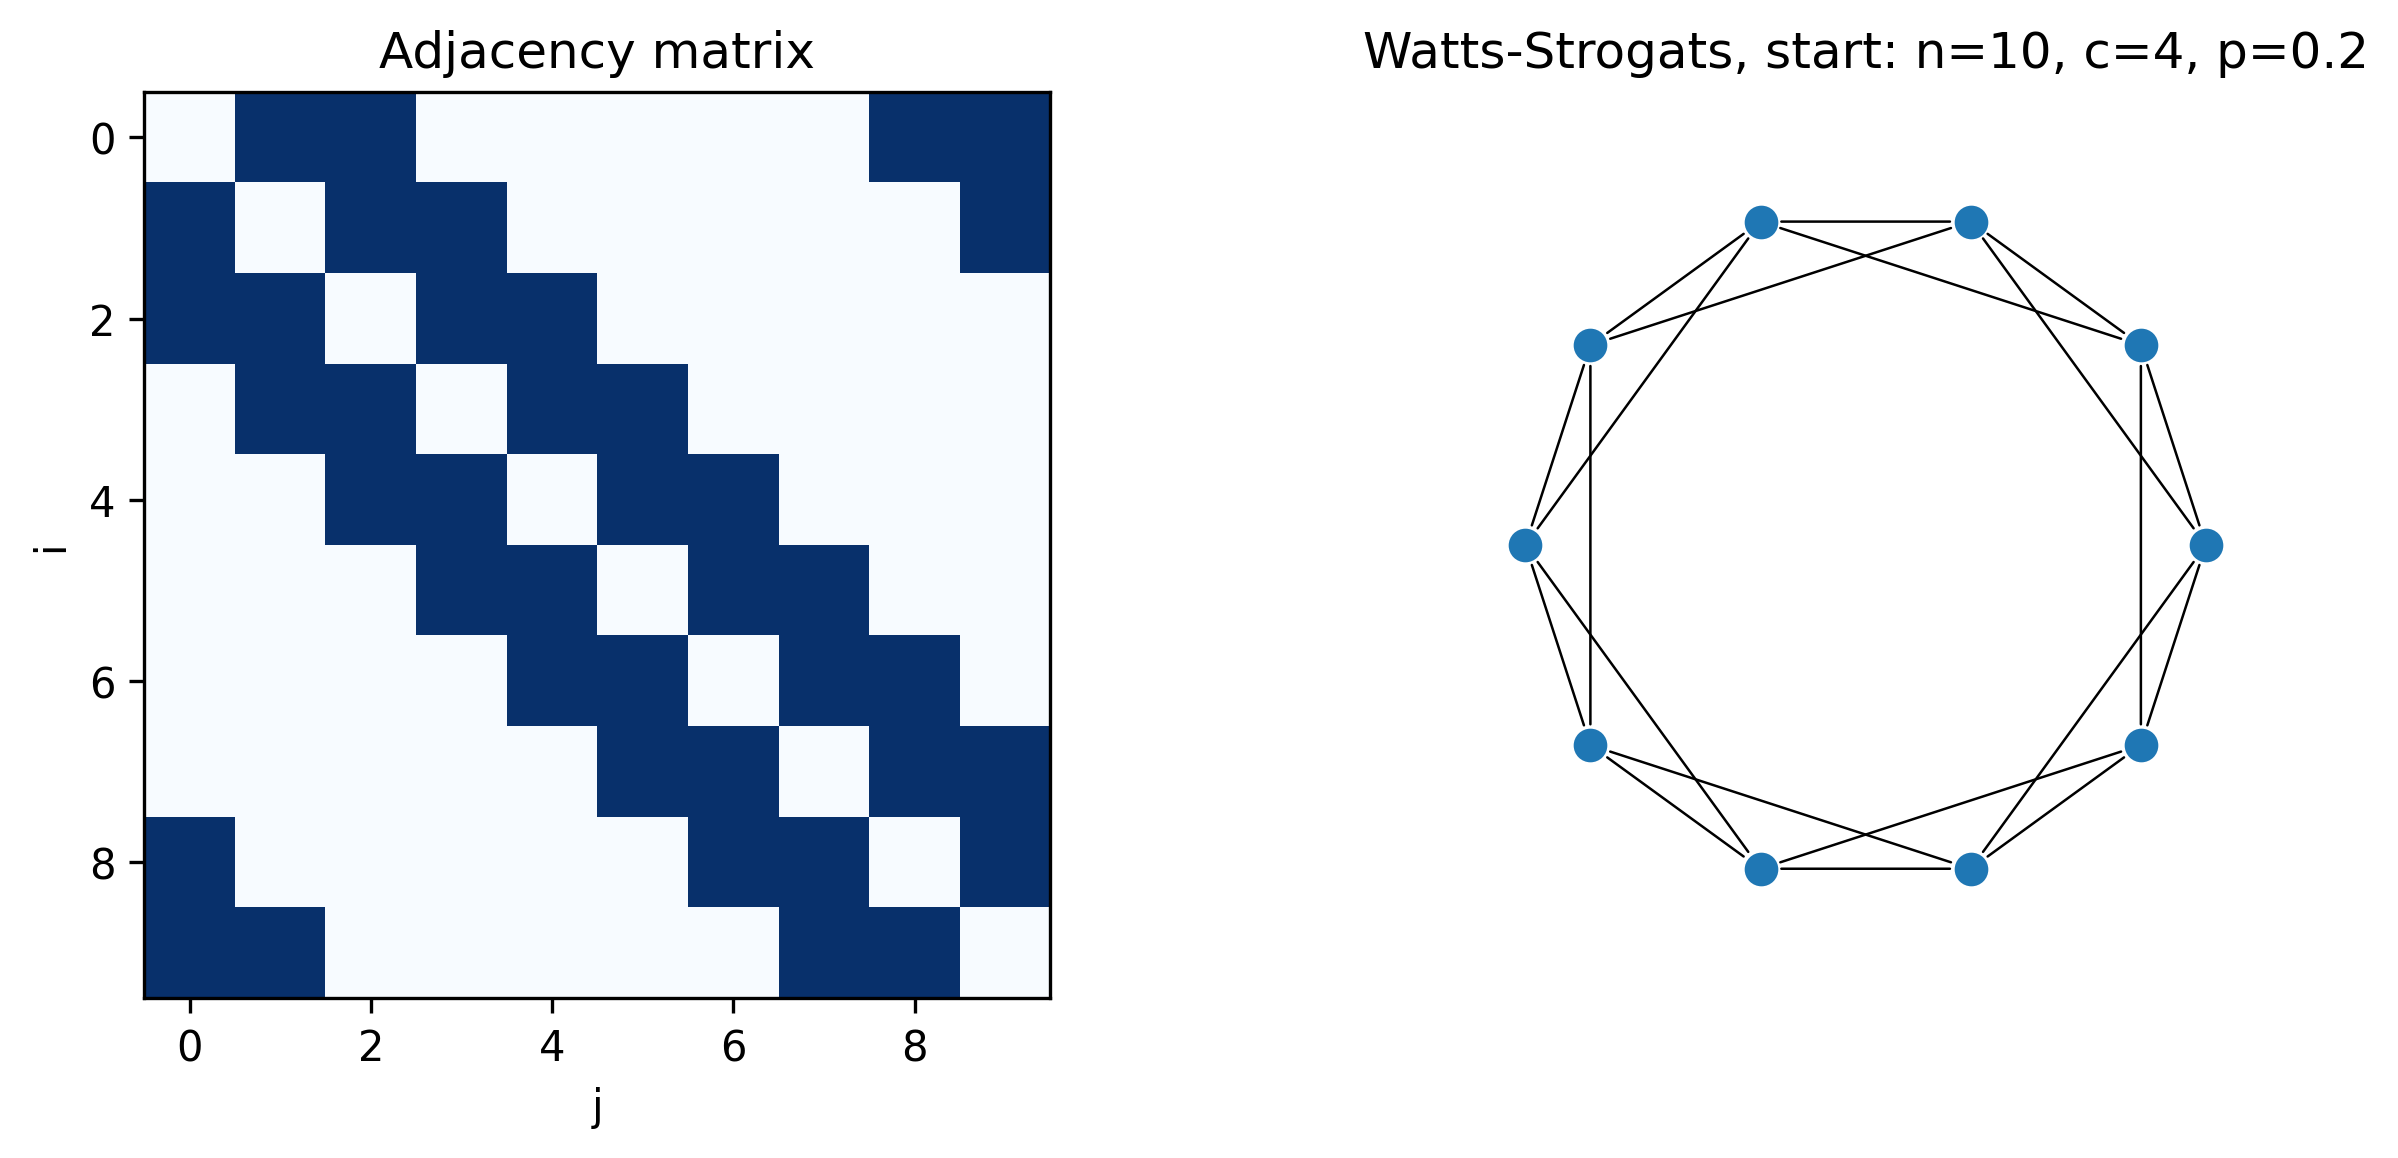

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

axes[0].imshow(A_0, cmap="Blues", vmin=0, vmax=1)
axes[0].set(
    title="Adjacency matrix", 
    xlabel="j", 
    ylabel="i"
)
vis.draw_network_dots(G_ws_0, ax=axes[1])
axes[1].set_title(f"Watts-Strogats, start: n={n}, c={c}, p={p}")
plt.show()

Now we perform the rewiring explicitly

In [11]:
rng = np.random.default_rng()

edges = nm.adjacency_to_edges(A)

for i, j in edges:
    if rng.random() < p:

        available = np.setdiff1d(
            np.arange(n),
            np.append(np.flatnonzero(A[i, :]), i)
        )

        if len(available) > 0:
            k = rng.choice(available)

            A[i, j] = A[j, i] = 0
            A[i, k] = A[k, i] = 1
            
G_ws_1 = nx.from_numpy_array(A)
A_1 = A.copy()

print(f"Number of edges: {A.sum() / 2}")
print(f"expected: {n * c // 2}")

Number of edges: 20.0
expected: 20


Let's plot the rewired graph:

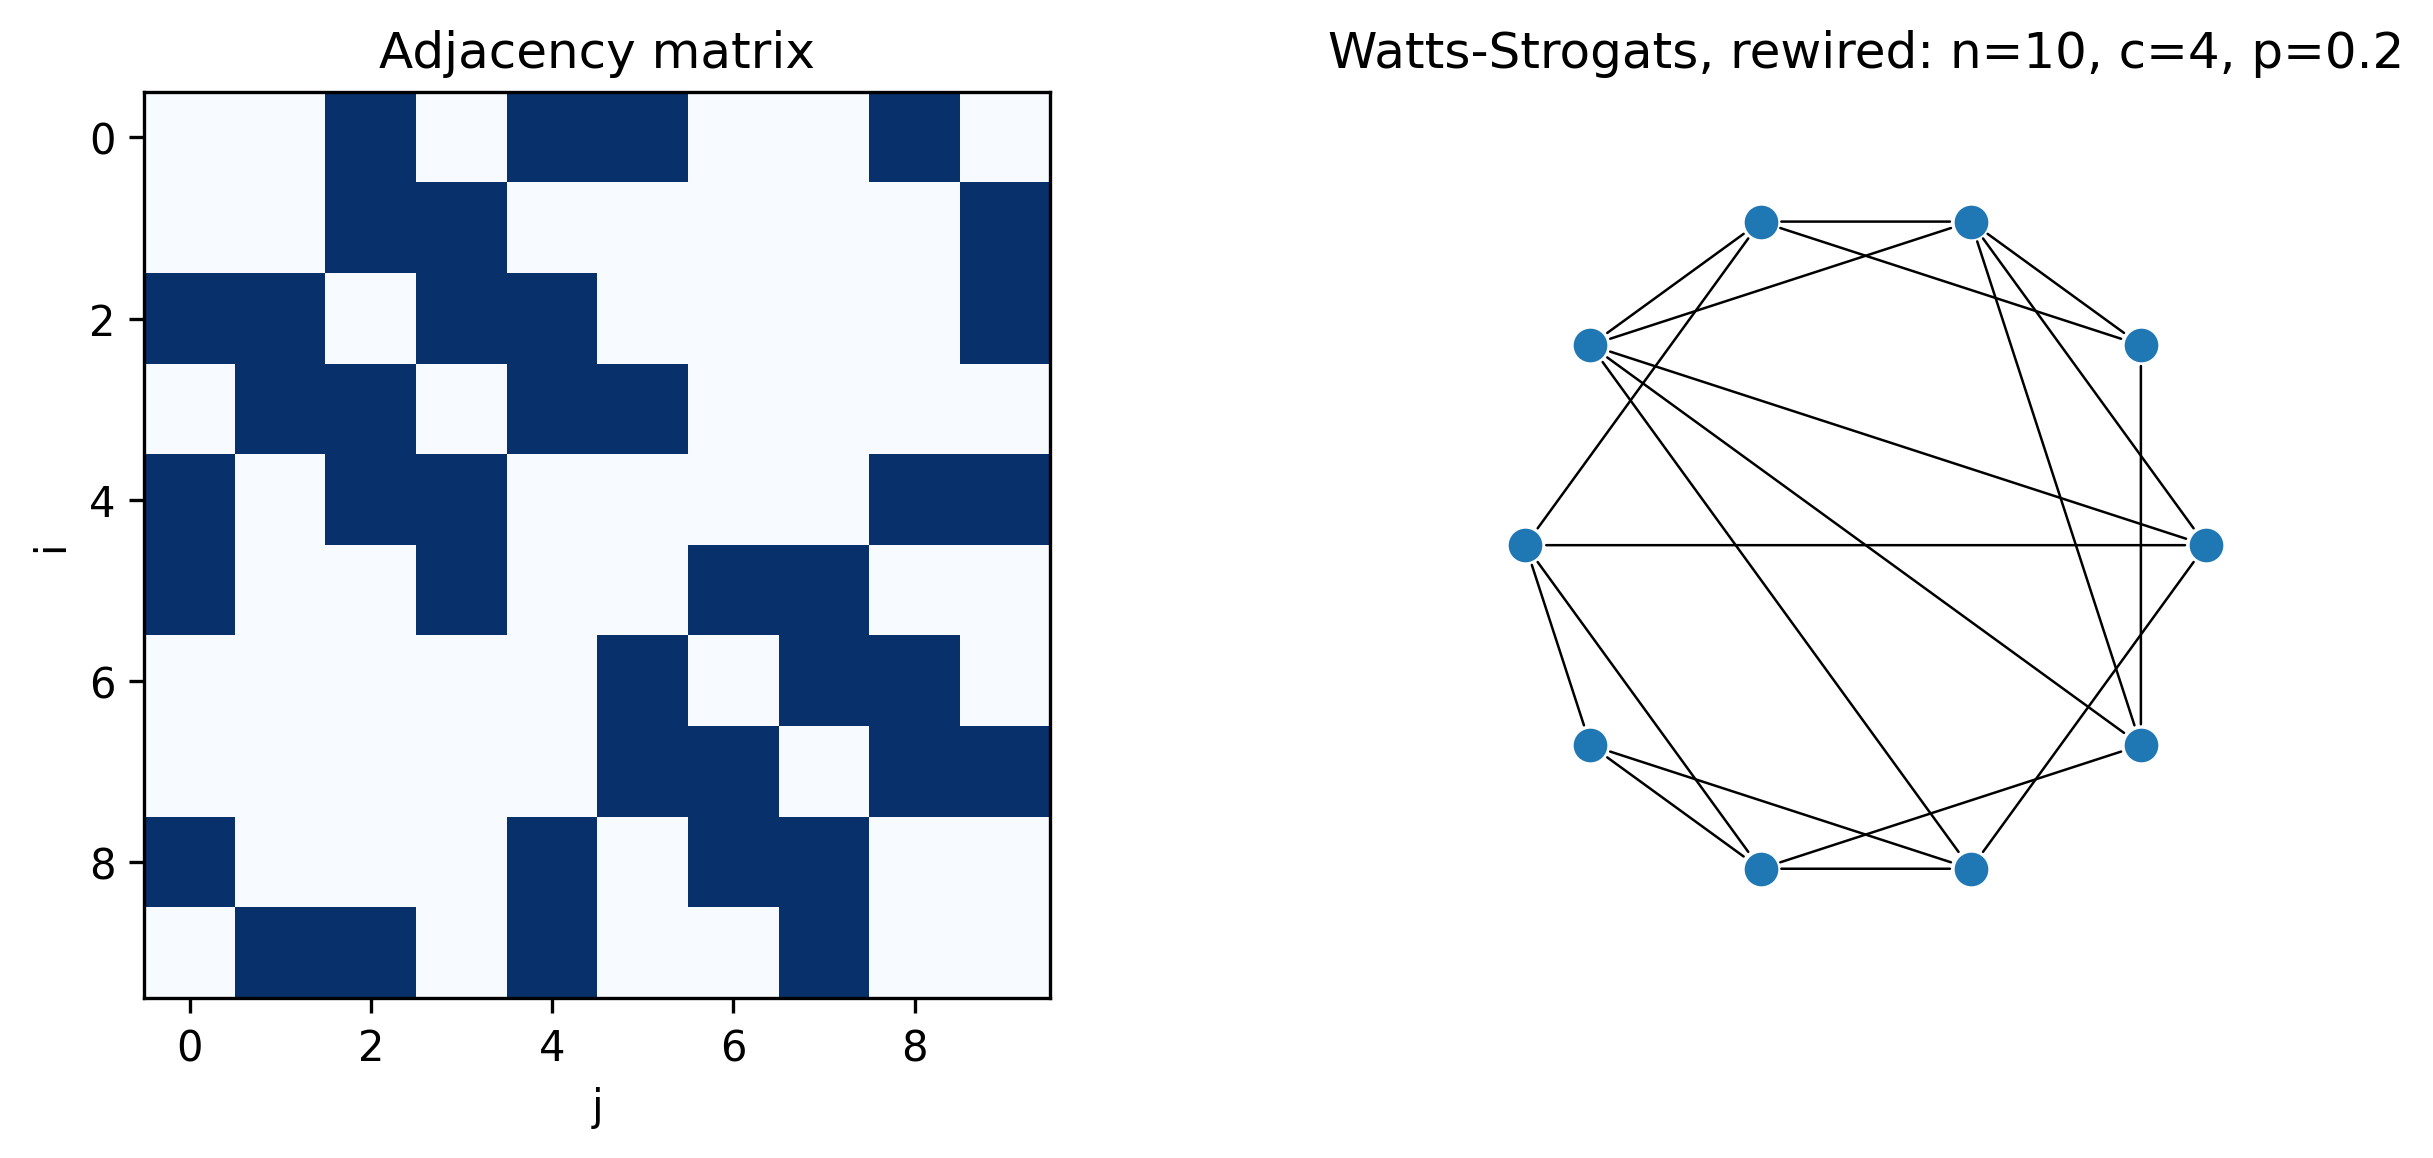

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

axes[0].imshow(A_1, cmap="Blues", vmin=0, vmax=1)
axes[0].set(
    title="Adjacency matrix", 
    xlabel="j", 
    ylabel="i"
)
vis.draw_network_dots(G_ws_1, ax=axes[1])
axes[1].set_title(f"Watts-Strogats, rewired: n={n}, c={c}, p={p}")
plt.show()

Let's compare the two graphs (starting point, after rewiring)

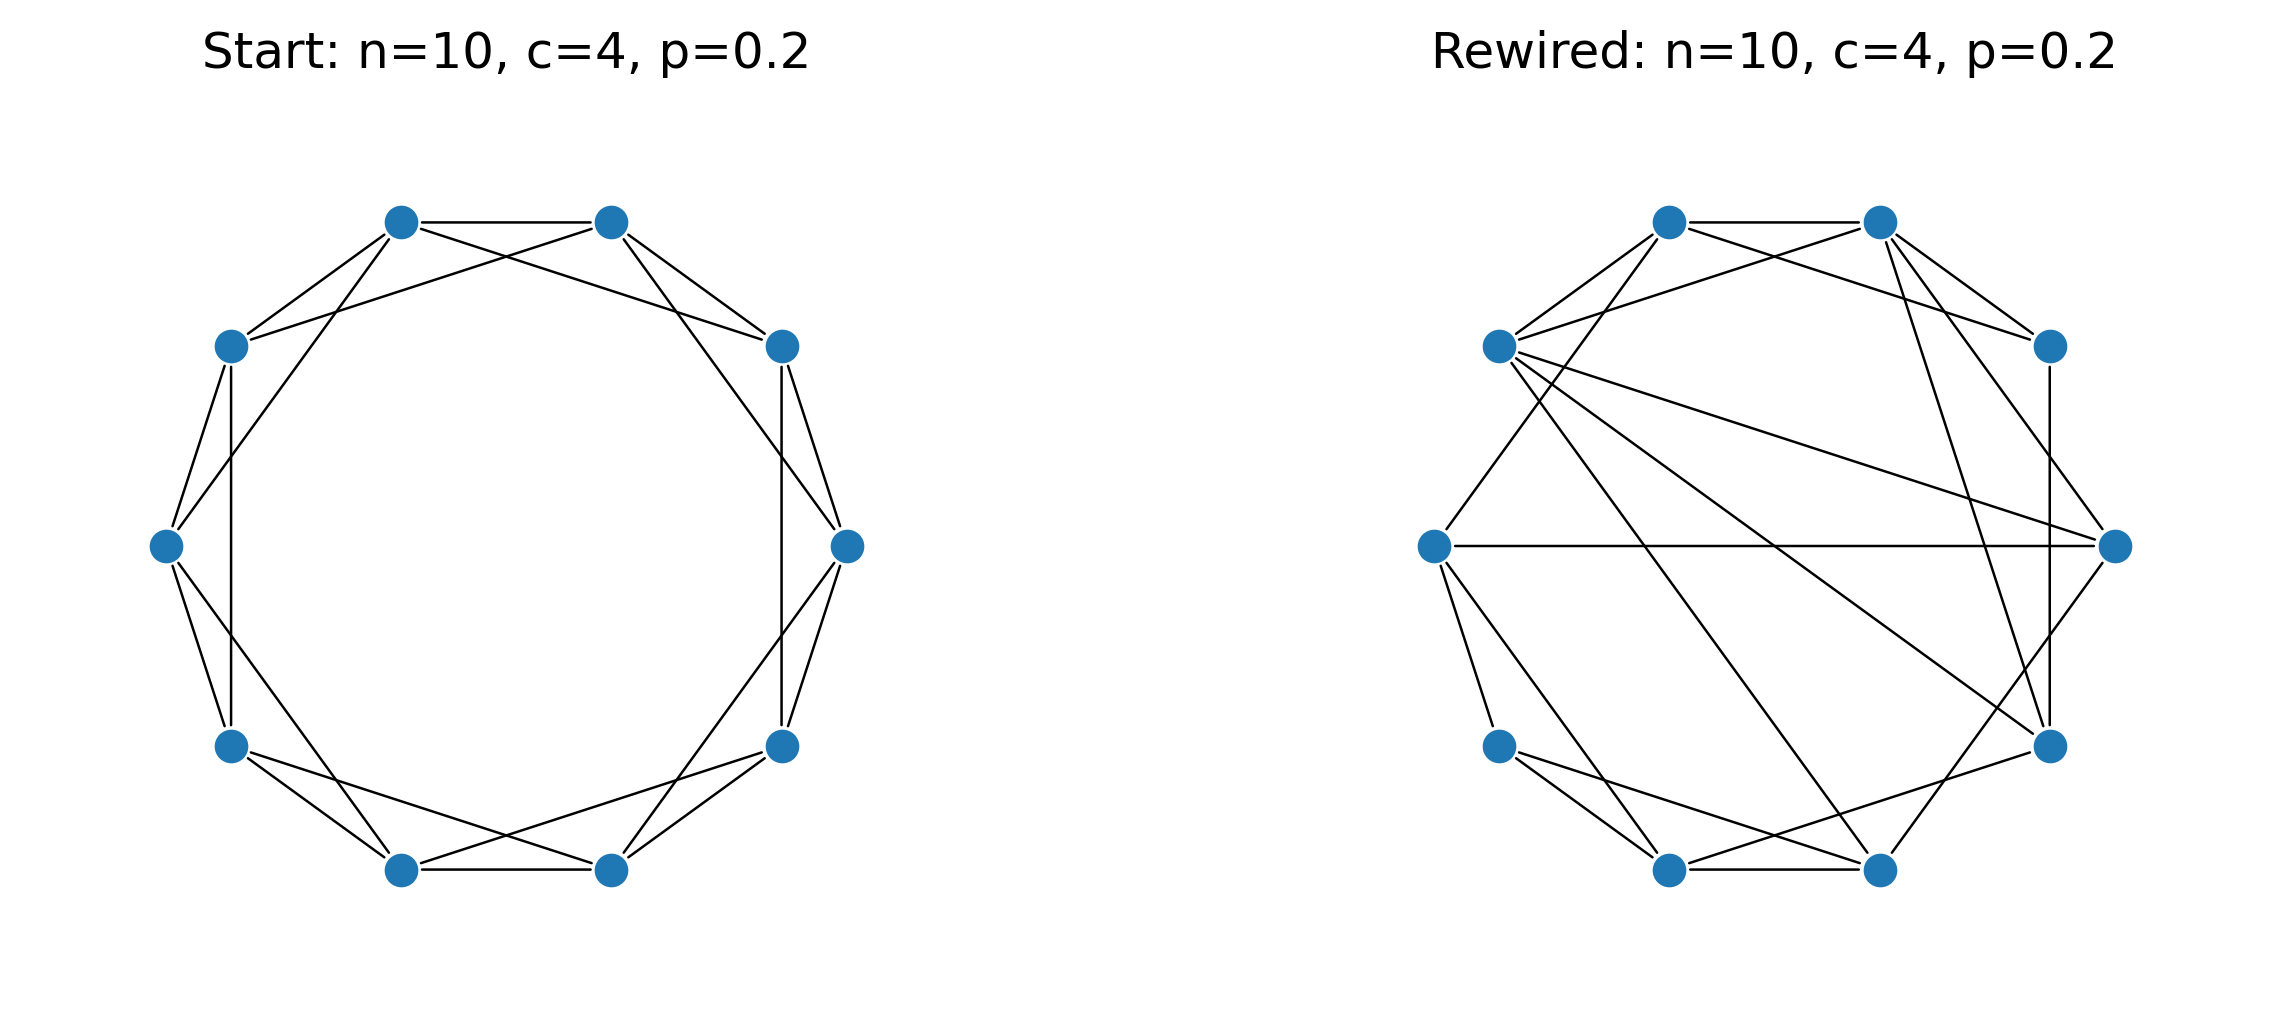

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

vis.draw_network_dots(G_ws_0, ax=axes[0])
axes[0].set_title(f"Start: n={n}, c={c}, p={p}")
vis.draw_network_dots(G_ws_1, ax=axes[1])
axes[1].set_title(f"Rewired: n={n}, c={c}, p={p}")
plt.show()

### Exercise 12.5

How the mean path length $l$ and the clustering coefficient $C$ for the Watts-Strogatz small-world graph depend on $p$ and $c$ parameters.

In [14]:
n = 200
c = 6

p_values = np.logspace(-3, 0, 25)

repetitions = 3

l = []  # mean path length
for probability in p_values:
    runs = [nm.graph_summary(nm.watts_strogatz(n, c, probability))
            for _ in range(repetitions)]
    l.append(np.mean([r["mean_path_lcc"] for r in runs]))

Theory (average path length)

In [15]:
# average path length, p=0 limit
l_0 = n / (2 * c)

# average path length, p=1 limit
l_1 = np.log(n) / np.log(c)

Let's plot:

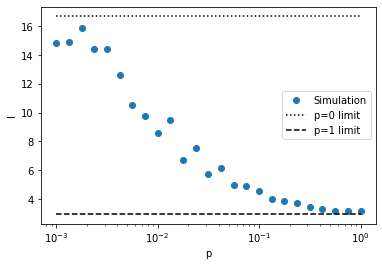

In [16]:
plt.plot(p_values, l, "o", label="Simulation")
plt.plot(p_values, l_0 + 0 * p_values, "k:", label="p=0 limit")
plt.plot(p_values, l_1 + 0 * p_values, "k--", label="p=1 limit")
plt.xlabel("p")
plt.ylabel("l")
plt.legend()
plt.xscale("log")

In [17]:
n = 100
p = 0.0

c_values = (np.arange(0, n // 2, 2) + 2).astype(int)

repetitions = 3

C = []  # clustering coefficient
for c in c_values:
    runs = [nm.graph_summary(nm.watts_strogatz(n, c, p))
            for _ in range(repetitions)]
    C.append(np.mean([r["C"] for r in runs]))


Theory (clustering coefficient)

In [18]:
# clustering coefficient, p=0 limit

C0 = 3 * (c_values - 2) / (4 * (c_values - 1))

Let's plot the clustering coefficient $C$ for the Watts-Strogats small-world graph as a function of $c$

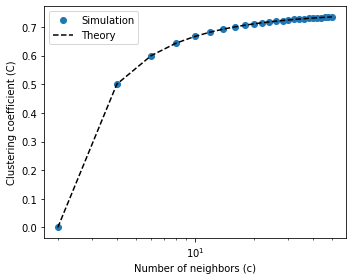

In [19]:
plt.figure(figsize=(5, 4))

plt.plot(c_values, C, "o", label="Simulation")
plt.plot(c_values, C0, "k--", label="Theory")

plt.xlabel("Number of neighbors (c)")
plt.ylabel("Clustering coefficient (C)")
plt.xscale("log")
plt.legend()

plt.tight_layout()
plt.show()

<a id="questions"></a>
## Questions

- [Q5: Erdős–Rényi random graph](#q5)

- [Q6: Erdős–Rényi random graph: mean path length and clustering coefficient](#q6)

- [Q7: Watts-Strogatz small-world graph](#q7)

- [Q8: Watts-Strogatz small-world graph: mean path length and clustering coefficient](#q8)

<a id="q5"></a>
### Q5: Erdős–Rényi random graph

[Go back to questions](#questions)


Refer to **Section 12.3, "Erdős–Rényi random graphs"**, where the notebook constructs a random graph using `n = 40` and `p = 0.10`.

**a.** What does the parameter `p` control in the code? What would the network look like if `p = 0` or `p = 1`?

**b.** The code constructs the adjacency matrix using:

    for i in range(n):
        for j in range(i + 1, n):
            if np.random.random() < p:
                A[i, j] = 1
                A[j, i] = 1

Why does the inner loop start at `i + 1`? What would happen if it started at `0` instead?

**c.** The notebook compares the measured mean degree with the theoretical prediction `(n - 1) * p`. Why might these values differ? Keeping `p` fixed, would you expect the relative difference to be smaller for a network with fewer or more nodes? Explain.

<a id="q6"></a>
### Q6: Erdős–Rényi random graph: mean path length and clustering coefficient

[Go back to questions](#questions)


Refer to **Exercise 12.4 in Section 12.3**, where the notebook generates random graphs for different values of `p` and calculates the mean path length `l` and clustering coefficient `C`.

**a.** The notebook contains the following code:

    repetitions = 4
    runs = [nm.graph_summary(nm.erdos_renyi(n, probability))
            for _ in range(repetitions)]

Why does the notebook generate four networks for each value of `p` instead of just one?

**b.** The notebook compares the simulated clustering coefficient with the theoretical prediction $C \approx p$. Explain intuitively why increasing `p` increases clustering.

**c.** In Exercise 12.4, suppose we increase `p` while keeping `n` fixed. Would the number of edges, clustering coefficient, and mean shortest-path length all change in the same direction? Explain why.




<a id="q7"></a>
### Q7: Watts-Strogatz small-world graph

[Go back to questions](#questions)

Refer to **Section 12.4, "Watts–Strogatz small-world graphs"**, where the notebook constructs a regular ring lattice with `n = 10`, `c = 4`, and then rewires edges with probability `p = 0.2`.

**a.** What does the parameter `c` represent? What would change in the initial network if `c` were increased from 4 to 6?

**b.** In the rewiring code, the following statements appear:

    A[i, j] = A[j, i] = 0
    A[i, k] = A[k, i] = 1

Explain what these statements do. Why does the total number of edges remain unchanged?

**c.** Consider the regular ring lattice with `n = 6` and `c = 2`. Can you rearrange its edges so that the network changes, but the number of edges, degree of every node, and clustering coefficient all remain unchanged? Illustrate your answer with a sketch.



<a id="q8"></a>
### Q8: Watts-Strogatz small-world graph: mean path length and clustering coefficient

[Go back to questions](#questions)

Refer to **Exercise 12.5 in Section 12.4**, where the notebook investigates how the mean path length depends on rewiring probability `p` and how the clustering coefficient depends on the initial number of neighbors `c`.

**a.** The notebook uses:

    p_values = np.logspace(-3, 0, 25)

Why does the notebook use logarithmically spaced values of `p` rather than equally spaced values?

**b.** In the second part of Exercise 12.5, the notebook calculates the clustering coefficient using:

    n = 100
    p = 0.0

    c_values = (np.arange(0, n // 2, 2) + 2).astype(int)

Why must `c` take even values in the Watts–Strogatz model?

**c.** Examine the mean path length plot in Exercise 12.5. The notebook keeps `n = 200` and `c = 6` fixed while varying `p`. Why can the mean path length decrease substantially even though the total number of edges remains unchanged? Explain why this decrease can occur even for small values of `p`.